In [1]:
# =====================================================
# Version 5: Advanced Lasso
# Cross Validation + Feature Selection
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    KFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import Lasso

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    make_scorer
)


# =====================================================
# 1. 데이터 불러오기
# =====================================================

train_raw = pd.read_csv('modulabs-di/train.csv')
test_raw = pd.read_csv('modulabs-di/test.csv')

y = train_raw['SalePrice']
test_ids = test_raw['Id']

X = train_raw.drop(
    columns=['SalePrice', 'Id']
)

X_test = test_raw.drop(
    columns=['Id']
)

print("Train shape:", X.shape)
print("Test shape:", X_test.shape)

Train shape: (1168, 79)
Test shape: (292, 79)


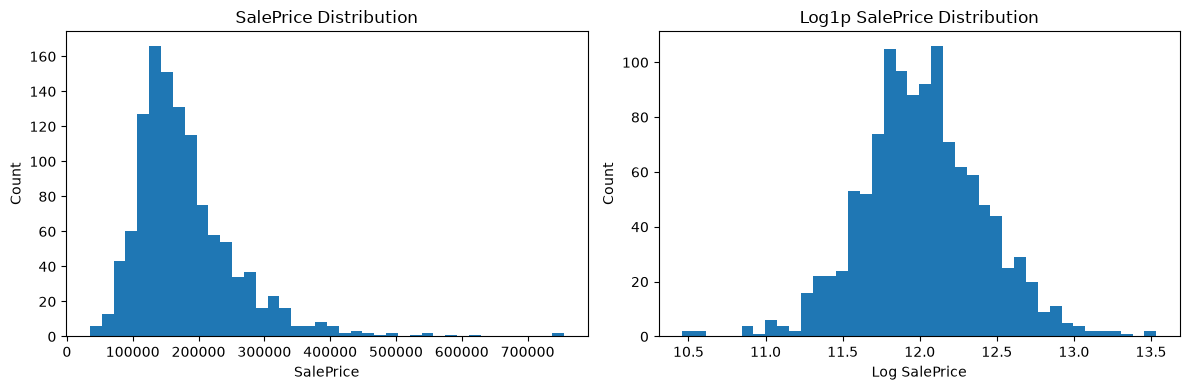

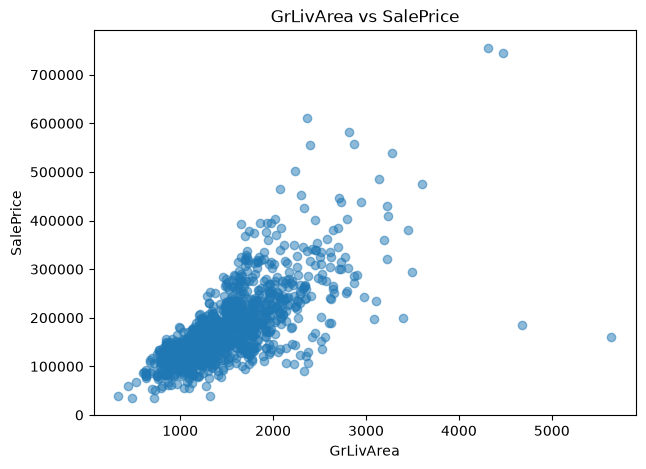

In [2]:
# =====================================================
# 2. 데이터 분포 확인
# =====================================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(y, bins=40)
axes[0].set_title('SalePrice Distribution')
axes[0].set_xlabel('SalePrice')
axes[0].set_ylabel('Count')

axes[1].hist(np.log1p(y), bins=40)
axes[1].set_title('Log1p SalePrice Distribution')
axes[1].set_xlabel('Log SalePrice')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()


# 주요 변수와 SalePrice 관계
plt.figure(figsize=(7, 5))

plt.scatter(
    X['GrLivArea'],
    y,
    alpha=0.5
)

plt.xlabel('GrLivArea')
plt.ylabel('SalePrice')
plt.title('GrLivArea vs SalePrice')

plt.show()

In [3]:
# =====================================================
# 3. 구조적 결측치 처리
# =====================================================

none_cols = [
    'Alley', 'BsmtQual', 'BsmtCond', 'BsmtExposure',
    'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu',
    'GarageType', 'GarageFinish', 'GarageQual',
    'GarageCond', 'PoolQC', 'Fence', 'MiscFeature',
    'MasVnrType'
]

zero_cols = [
    'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF',
    'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath',
    'GarageYrBlt', 'GarageCars', 'GarageArea',
    'MasVnrArea'
]

def fill_structural_missing(df):

    df = df.copy()

    for col in none_cols:
        if col in df.columns:
            df[col] = df[col].fillna('None')

    for col in zero_cols:
        if col in df.columns:
            df[col] = df[col].fillna(0)

    return df


X = fill_structural_missing(X)
X_test = fill_structural_missing(X_test)


In [4]:
# =====================================================
# 4. Feature Engineering
# =====================================================

def make_features(df):

    df = df.copy()

    # 전체 주택 면적
    df['TotalSF'] = (
        df['TotalBsmtSF']
        + df['1stFlrSF']
        + df['2ndFlrSF']
    )

    # 전체 욕실 수
    df['TotalBath'] = (
        df['FullBath']
        + 0.5 * df['HalfBath']
        + df['BsmtFullBath']
        + 0.5 * df['BsmtHalfBath']
    )

    # 포치 및 데크 면적
    df['TotalPorchSF'] = (
        df['OpenPorchSF']
        + df['EnclosedPorch']
        + df['3SsnPorch']
        + df['ScreenPorch']
        + df['WoodDeckSF']
    )

    # 주택 연식
    df['HouseAge'] = (
        df['YrSold'] - df['YearBuilt']
    )

    # 리모델링 이후 경과 연수
    df['RemodAge'] = (
        df['YrSold'] - df['YearRemodAdd']
    )

    # 품질과 생활 면적의 결합
    df['QualityArea'] = (
        df['OverallQual'] * df['GrLivArea']
    )

    # 차고 면적 비율
    df['GarageAreaRatio'] = (
        df['GarageArea']
        / (df['GrLivArea'] + 1)
    )

    # 시설 보유 여부
    df['HasBasement'] = (
        df['TotalBsmtSF'] > 0
    ).astype(int)

    df['HasGarage'] = (
        df['GarageArea'] > 0
    ).astype(int)

    df['HasFireplace'] = (
        df['Fireplaces'] > 0
    ).astype(int)

    df['HasPool'] = (
        df['PoolArea'] > 0
    ).astype(int)

    # 품질의 비선형 효과
    df['OverallQualSquared'] = (
        df['OverallQual'] ** 2
    )

    return df


X = make_features(X)
X_test = make_features(X_test)

In [5]:
# =====================================================
# 5. 수치형 / 범주형 변수 구분
# =====================================================

categorical_cols = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numeric_cols = X.select_dtypes(
    include='number'
).columns.tolist()

print("Categorical features:", len(categorical_cols))
print("Numeric features:", len(numeric_cols))


# =====================================================
# 6. 전처리 파이프라인
# =====================================================

categorical_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='most_frequent')
    ),
    (
        'onehot',
        OneHotEncoder(handle_unknown='ignore')
    )
])

numeric_pipeline = Pipeline([
    (
        'imputer',
        SimpleImputer(strategy='median')
    ),
    (
        'scaler',
        StandardScaler()
    )
])

preprocessor = ColumnTransformer([
    ('cat', categorical_pipeline, categorical_cols),
    ('num', numeric_pipeline, numeric_cols)
])


Categorical features: 43
Numeric features: 48


C:\Users\chaee\AppData\Local\Temp\ipykernel_21700\1624094511.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [6]:
# =====================================================
# 7. 학습 / 검증 데이터 분리
# =====================================================

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

y_train_log = np.log1p(y_train)


# =====================================================
# 8. RMSE 평가 함수
# =====================================================

def original_rmse(y_true_log, y_pred_log):

    y_true = np.expm1(y_true_log)
    y_pred = np.expm1(y_pred_log)

    return -np.sqrt(
        mean_squared_error(y_true, y_pred)
    )


rmse_scorer = make_scorer(original_rmse)

In [7]:
# =====================================================
# 9. 5-Fold Cross Validation
# =====================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [8]:
# =====================================================
# 10. Alpha 세밀하게 탐색
# =====================================================

alpha_values = np.geomspace(
    0.00001,
    0.1,
    35
)

lasso_pipeline = Pipeline([
    ('preprocessor', preprocessor),

    ('regressor', Lasso(
        max_iter=200000,
        tol=0.0001
    ))
])

param_grid = {
    'regressor__alpha': alpha_values
}


grid_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=param_grid,
    scoring=rmse_scorer,
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid_search.fit(
    X_train,
    y_train_log
)


# =====================================================
# 11. 최적 Alpha 확인
# =====================================================

best_model = grid_search.best_estimator_

best_alpha = grid_search.best_params_[
    'regressor__alpha'
]

cv_rmse = -grid_search.best_score_

print("\n===== Cross Validation Results =====")

print("Best Alpha:", best_alpha)

print("Best CV RMSE:", round(cv_rmse, 2))


===== Cross Validation Results =====
Best Alpha: 0.0017190722018585747
Best CV RMSE: 50090.19


In [9]:
# =====================================================
# 12. 검증 데이터 성능 평가
# =====================================================

valid_pred_log = best_model.predict(X_valid)

valid_pred = np.expm1(valid_pred_log)

valid_pred = np.maximum(valid_pred, 0)

valid_rmse = np.sqrt(
    mean_squared_error(y_valid, valid_pred)
)

valid_mae = mean_absolute_error(
    y_valid,
    valid_pred
)

print("\n===== Validation Results =====")

print("Validation RMSE:", round(valid_rmse, 2))
print("Validation MAE:", round(valid_mae, 2))


===== Validation Results =====
Validation RMSE: 23190.51
Validation MAE: 15469.26



===== Alpha Comparison =====
 param_regressor__alpha      CV_RMSE  std_test_score
               0.001719 50090.185029    35909.882864
               0.058171 50103.590265    19721.285256
               0.044367 50221.276535    23566.129494
               0.002254 50316.925109    35815.755712
               0.076270 50501.048359    15488.129619
               0.033839 50671.739510    27003.058451
               0.001311 50914.942752    38822.382245
               0.000763 51205.956947    42580.681304
               0.001000 51281.729940    41015.471338
               0.000582 51404.138440    44126.209665


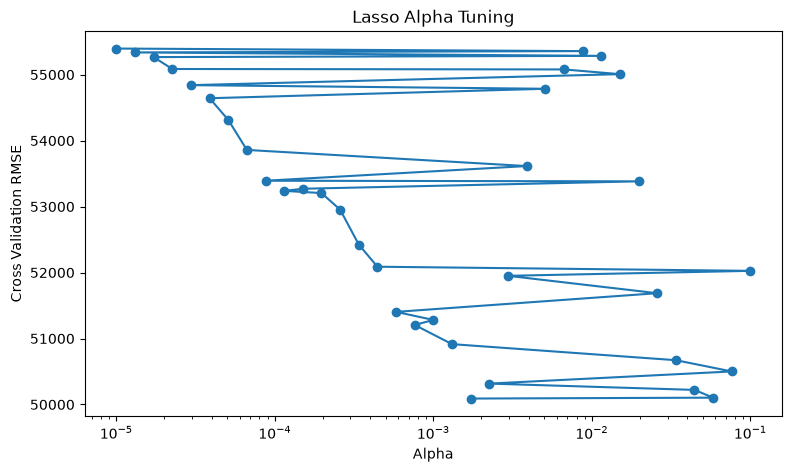

In [10]:
# =====================================================
# 13. Alpha별 성능 확인
# =====================================================

cv_results = pd.DataFrame(
    grid_search.cv_results_
)

alpha_result = cv_results[
    [
        'param_regressor__alpha',
        'mean_test_score',
        'std_test_score'
    ]
].copy()

alpha_result['CV_RMSE'] = (
    -alpha_result['mean_test_score']
)

alpha_result = alpha_result.sort_values(
    'CV_RMSE'
)

print("\n===== Alpha Comparison =====")

print(
    alpha_result[
        [
            'param_regressor__alpha',
            'CV_RMSE',
            'std_test_score'
        ]
    ].head(10).to_string(index=False)
)


# Alpha별 RMSE 시각화
plt.figure(figsize=(9, 5))

plt.plot(
    alpha_result['param_regressor__alpha'].astype(float),
    alpha_result['CV_RMSE'],
    marker='o'
)

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Cross Validation RMSE')
plt.title('Lasso Alpha Tuning')

plt.show()



In [11]:
# =====================================================
# 14. Feature Selection
# =====================================================

feature_names = (
    best_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

coefficients = (
    best_model
    .named_steps['regressor']
    .coef_
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

feature_importance['Abs_Coefficient'] = (
    feature_importance['Coefficient'].abs()
)

# Lasso가 선택한 변수
selected_features = feature_importance[
    feature_importance['Coefficient'] != 0
].copy()

# 제거된 변수
removed_features = feature_importance[
    feature_importance['Coefficient'] == 0
].copy()

print("\n===== Feature Selection Results =====")

print("전체 변수:", len(feature_importance))
print("선택된 변수:", len(selected_features))
print("제거된 변수:", len(removed_features))

print("\n===== Top 20 Important Features =====")

print(
    selected_features
    .sort_values('Abs_Coefficient', ascending=False)
    [['Feature', 'Coefficient']]
    .head(20)
    .to_string(index=False)
)


# =====================================================
# 15. 기존 Version 3와 비교
# =====================================================

version3_rmse = 19610.33

comparison = pd.DataFrame({
    'Model': [
        'Version 3 Lasso',
        'Version 5 Advanced Lasso'
    ],
    'Validation RMSE': [
        version3_rmse,
        valid_rmse
    ]
})

comparison['Difference'] = (
    comparison['Validation RMSE']
    - version3_rmse
)

print("\n===== Version Comparison =====")

print(comparison.to_string(index=False))



===== Feature Selection Results =====
전체 변수: 305
선택된 변수: 76
제거된 변수: 229

===== Top 20 Important Features =====
                   Feature  Coefficient
     cat__MSZoning_C (all)    -0.222814
            num__GrLivArea     0.104650
 cat__Neighborhood_Crawfor     0.072220
          cat__MSZoning_RM    -0.070046
          num__OverallQual     0.063307
 cat__Neighborhood_Edwards    -0.060985
       cat__KitchenQual_Ex     0.055575
      cat__Condition1_Norm     0.053787
           num__GarageCars     0.052601
          num__OverallCond     0.049913
cat__SaleCondition_Abnorml    -0.045978
   num__OverallQualSquared     0.045767
            num__TotalBath     0.041827
 cat__Neighborhood_Somerst     0.041314
      cat__LandContour_Bnk    -0.038986
 cat__Neighborhood_NridgHt     0.036959
             num__HouseAge    -0.036478
       cat__Functional_Typ     0.034806
         cat__CentralAir_N    -0.033521
          cat__BsmtQual_Ex     0.025852

===== Version Comparison =====
                

In [12]:
# 각 폴드의 RMSE 확인
cv_results = pd.DataFrame(grid_search.cv_results_)

fold_cols = [
    "split0_test_score",
    "split1_test_score",
    "split2_test_score",
    "split3_test_score",
    "split4_test_score"
]

print(cv_results.loc[grid_search.best_index_, fold_cols])

split0_test_score   -116614.403113
split1_test_score    -27830.914237
split2_test_score    -20038.155789
split3_test_score    -59147.322867
split4_test_score    -26820.129138
Name: 19, dtype: float64


In [13]:
from sklearn.model_selection import KFold
import pandas as pd
import numpy as np

kf = KFold(n_splits=5, shuffle=True, random_state=42)

fold_summary = []

for fold, (_, val_idx) in enumerate(kf.split(X_train)):
    fold_prices = y_train.iloc[val_idx]

    fold_summary.append({
        "Fold": fold,
        "Count": len(fold_prices),
        "Mean": fold_prices.mean(),
        "Median": fold_prices.median(),
        "Min": fold_prices.min(),
        "Max": fold_prices.max(),
        "Std": fold_prices.std()
    })

fold_summary = pd.DataFrame(fold_summary)

print(fold_summary.round(2))

   Fold  Count       Mean    Median    Min     Max       Std
0     0    187  174276.05  160000.0  55993  451950  70105.26
1     1    187  178563.28  158500.0  35311  582933  87174.13
2     2    187  175484.84  166000.0  34900  403000  60899.14
3     3    187  191391.56  172500.0  39300  755000  99546.81
4     4    186  171973.90  151700.0  40000  556581  79479.93


In [14]:
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Fold 0의 학습/검증 인덱스
train_idx, val_idx = list(kf.split(X_train))[0]

X_fold_train = X_train.iloc[train_idx]
X_fold_val = X_train.iloc[val_idx]

y_fold_train = y_train.iloc[train_idx]
y_fold_val = y_train.iloc[val_idx]

# Fold 0 모델 학습
fold_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(
        alpha=best_alpha,
        max_iter=50000
    ))
])

fold_model.fit(
    X_fold_train,
    np.log1p(y_fold_train)
)

# 예측
pred_log = fold_model.predict(X_fold_val)
pred_price = np.expm1(pred_log)

# 실제 가격과 예측 가격 비교
comparison = pd.DataFrame({
    "Actual": y_fold_val.values,
    "Predicted": pred_price,
})

comparison["Error"] = (
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Abs_Error"] = comparison["Error"].abs()

print("RMSE:", np.sqrt(mean_squared_error(
    comparison["Actual"],
    comparison["Predicted"]
)))

print("\n오차가 가장 큰 주택 10개")
print(
    comparison.sort_values(
        "Abs_Error",
        ascending=False
    ).head(10).round(2)
)

RMSE: 116614.40311335993

오차가 가장 큰 주택 10개
     Actual   Predicted       Error   Abs_Error
168  160000  1728154.77 -1568154.77  1568154.77
170  147000   289337.57  -142337.57   142337.57
18   395000   286275.28   108724.72   108724.72
174  311500   252770.29    58729.71    58729.71
95   385000   326814.22    58185.78    58185.78
73   210000   160035.95    49964.05    49964.05
178  200624   249340.92   -48716.92    48716.92
52   361919   318567.70    43351.30    43351.30
65   171000   214011.02   -43011.02    43011.02
142  374000   331512.14    42487.86    42487.86
